In [1]:
import sys
print(sys.executable)


C:\ProgramData\anaconda3\python.exe


In [2]:
!{sys.executable} -m pip install pmdarima


Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pmdarima as pm
print("✅ pmdarima installed:", pm.__version__)


✅ pmdarima installed: 2.1.1


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-darkgrid')
print("# Libraries loaded successfully!")

# Libraries loaded successfully!


In [5]:
print("Loading data...")

store_1 = pd.read_csv(
    'C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_1_data.csv'
)

# Correct date parsing
store_1['Date'] = pd.to_datetime(store_1['Date'], dayfirst=True)

# Filter open days only
store_1_open = store_1[store_1['Open'] == 1].copy()
store_1_open = store_1_open.sort_values('Date').reset_index(drop=True)

print("✅ Data loaded!")
print(f"Records: {len(store_1_open)}")
print(f"Date range: {store_1_open['Date'].min().date()} to {store_1_open['Date'].max().date()}")


Loading data...
✅ Data loaded!
Records: 781
Date range: 2013-01-02 to 2015-07-31


In [6]:
test_weeks = 6
test_start_date = store_1_open['Date'].max() - timedelta(weeks=test_weeks)

train = store_1_open[store_1_open['Date'] < test_start_date].copy()
test = store_1_open[store_1_open['Date'] >= test_start_date].copy()

print("="*80)
print("TRAIN/TEST SPLIT")
print("="*80)
print(f"Train: {len(train)} records ({train['Date'].min().date()} to {train['Date'].max().date()})")
print(f"Test:  {len(test)} records ({test['Date'].min().date()} to {test['Date'].max().date()})")
print(f"\n🎯 Goal: Beat baseline MAPE of 9.65%")

TRAIN/TEST SPLIT
Train: 744 records (2013-01-02 to 2015-06-18)
Test:  37 records (2015-06-19 to 2015-07-31)

🎯 Goal: Beat baseline MAPE of 9.65%


In [7]:
def check_stationarity(timeseries, title):
    """
    Perform Augmented Dickey-Fuller test to check stationarity
    """
    print(f"="*80)
    print(f"STATIONARITY TEST: {title}")
    print(f"="*80)
    
    # Augmented Dickey-Fuller test
    result = adfuller(timeseries.dropna())
    
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print(f'Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')
    
    # Interpretation
    if result[1] <= 0.05:
        print(f"\n Data IS stationary (p-value ≤ 0.05)")
        print(f"   → Can use ARIMA without differencing (d=0)")
    else:
        print(f"\n Data is NOT stationary (p-value > 0.05)")
        print(f"   → Need differencing to make it stationary (d=1 or d=2)")
    
    return result[1] <= 0.05

# Test original sales data
is_stationary = check_stationarity(train['Sales'], "Original Sales Data")

STATIONARITY TEST: Original Sales Data
ADF Statistic: -5.3050
p-value: 0.0000
Critical Values:
	1%: -3.439
	5%: -2.866
	10%: -2.569

 Data IS stationary (p-value ≤ 0.05)
   → Can use ARIMA without differencing (d=0)


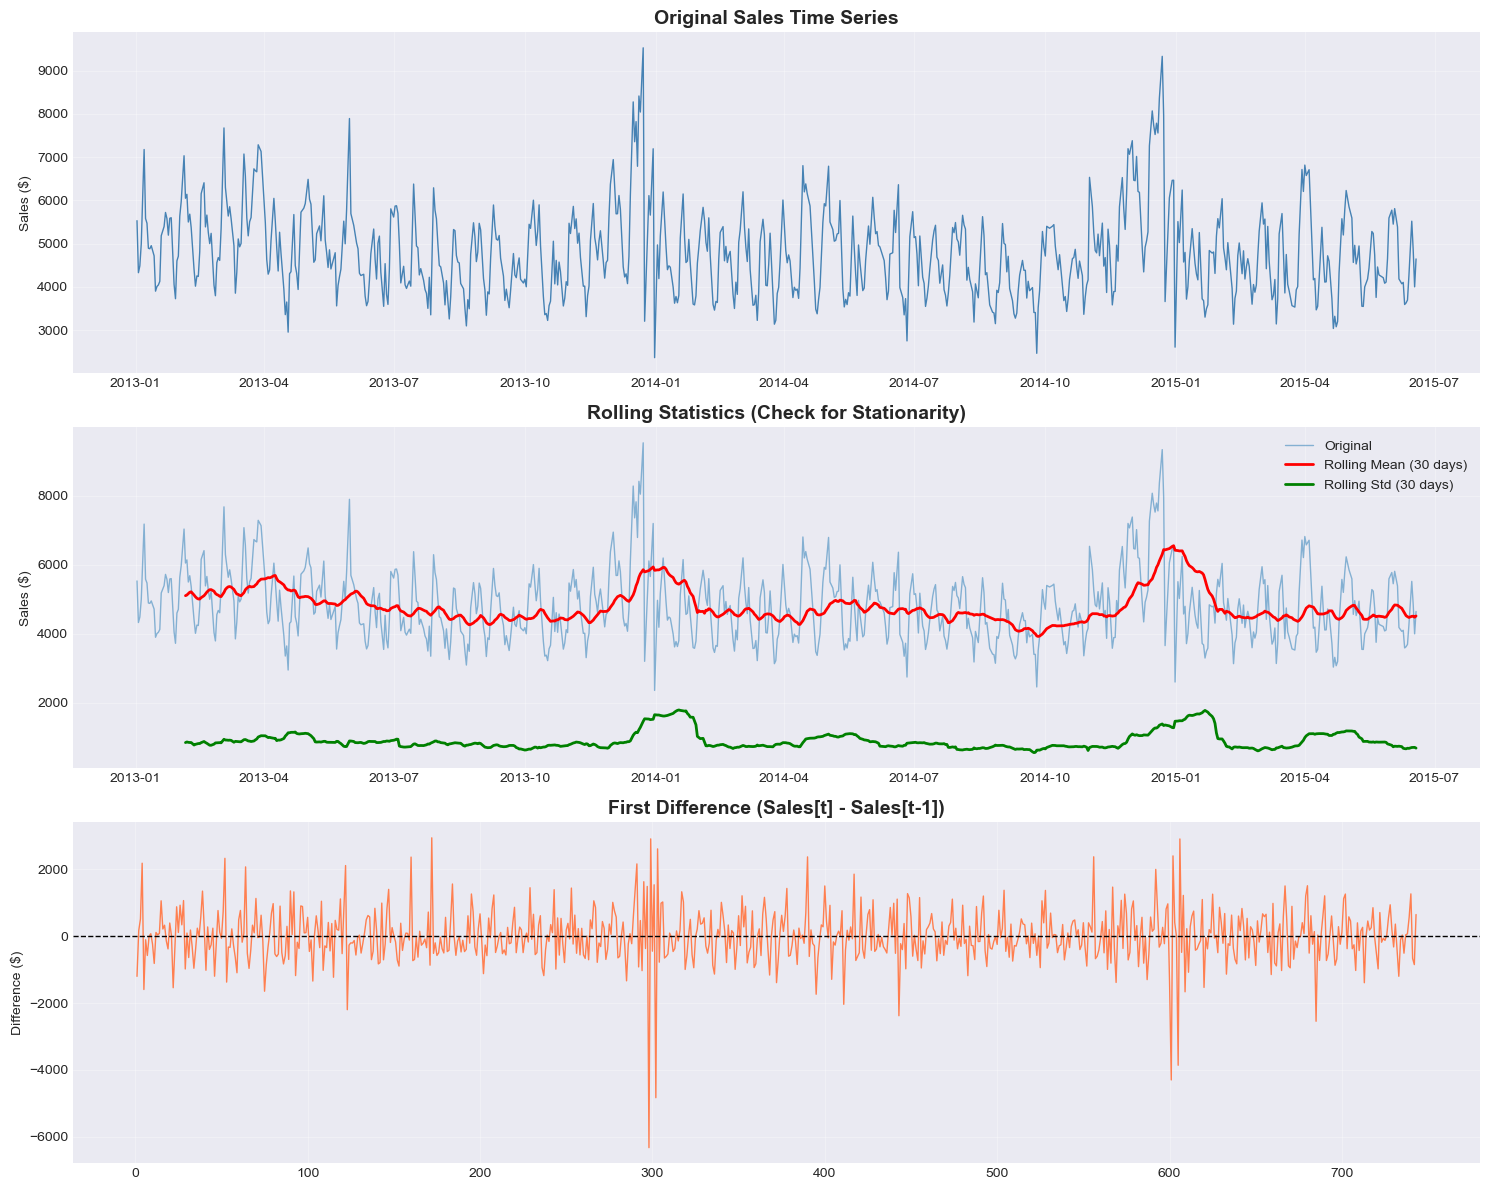

In [8]:
# Visualize to understand stationarity
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Original series
axes[0].plot(train['Date'], train['Sales'], linewidth=1, color='steelblue')
axes[0].set_title('Original Sales Time Series', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(alpha=0.3)

# Rolling mean and std (should be constant if stationary)
rolling_mean = train['Sales'].rolling(window=30).mean()
rolling_std = train['Sales'].rolling(window=30).std()

axes[1].plot(train['Date'], train['Sales'], label='Original', alpha=0.5, linewidth=1)
axes[1].plot(train['Date'], rolling_mean, label='Rolling Mean (30 days)', linewidth=2, color='red')
axes[1].plot(train['Date'], rolling_std, label='Rolling Std (30 days)', linewidth=2, color='green')
axes[1].set_title('Rolling Statistics (Check for Stationarity)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Sales ($)')
axes[1].legend()
axes[1].grid(alpha=0.3)

# First difference (if needed)
train_diff = train['Sales'].diff().dropna()
axes[2].plot(train_diff.index, train_diff.values, linewidth=1, color='coral')
axes[2].axhline(0, color='black', linestyle='--', linewidth=1)
axes[2].set_title('First Difference (Sales[t] - Sales[t-1])', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Difference ($)')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Check if differencing makes it stationary
if not is_stationary:
    print("\n" + "="*80)
    print("Testing First Difference:")
    is_stationary_diff = check_stationarity(train_diff, "First Differenced Data")


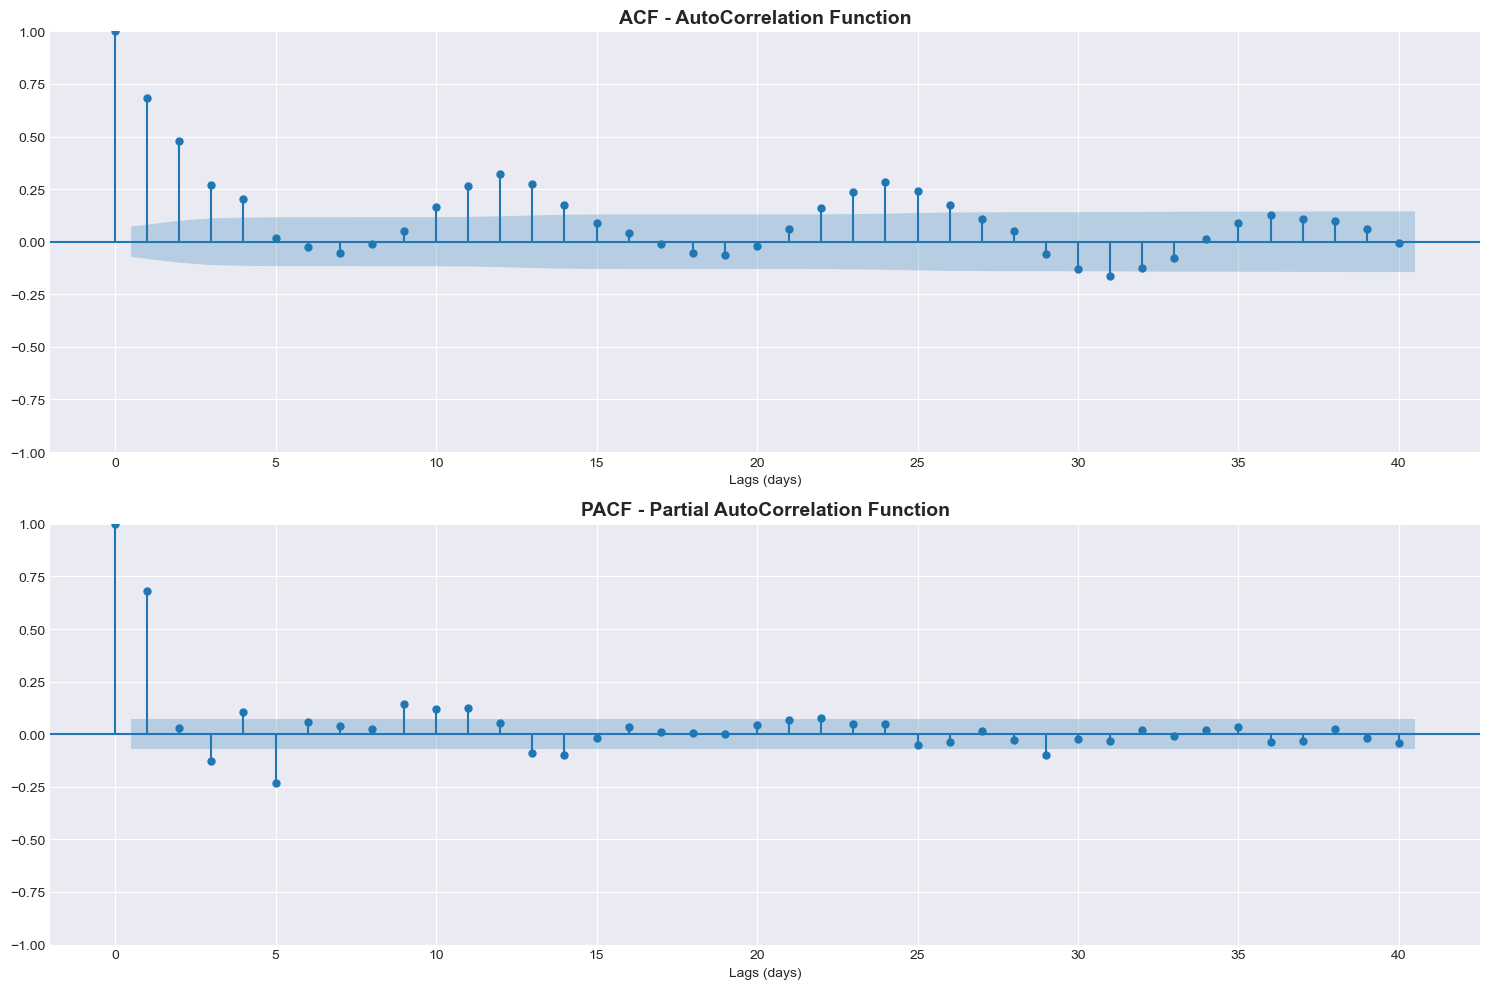

# How to read these plots:
  - ACF: Significant spikes suggest MA terms (q)
  - PACF: Significant spikes suggest AR terms (p)
  - Spikes at lag 7 suggest weekly seasonality


In [9]:
#Plot ACF and PACF
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# ACF Plot
plot_acf(train['Sales'].dropna(), lags=40, ax=axes[0])
axes[0].set_title('ACF - AutoCorrelation Function', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Lags (days)')

# PACF Plot
plot_pacf(train['Sales'].dropna(), lags=40, ax=axes[1])
axes[1].set_title('PACF - Partial AutoCorrelation Function', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Lags (days)')

plt.tight_layout()
plt.show()

print("# How to read these plots:")
print("  - ACF: Significant spikes suggest MA terms (q)")
print("  - PACF: Significant spikes suggest AR terms (p)")
print("  - Spikes at lag 7 suggest weekly seasonality")

In [10]:
print("="*80)
print("RUNNING AUTO ARIMA (This may take 2-3 minutes...)")
print("="*80)

# Auto ARIMA to find best parameters
auto_model = pm.auto_arima(
    train['Sales'],
    start_p=0, start_q=0,
    max_p=5, max_q=5,
    d=None,  # Let it determine d automatically
    seasonal=False,  # Start with non-seasonal
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True  # Print the search process
)

print("\n" + "="*80)
print("BEST ARIMA MODEL FOUND:")
print("="*80)
print(auto_model.summary())

best_order = auto_model.order
print(f"\n✅ Best ARIMA parameters: {best_order}")
print(f"   p (AR order): {best_order[0]}")
print(f"   d (Differencing): {best_order[1]}")
print(f"   q (MA order): {best_order[2]}")

RUNNING AUTO ARIMA (This may take 2-3 minutes...)
Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=14752.439, Time=0.11 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=12088.296, Time=0.04 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=13960.558, Time=0.22 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.07 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=12064.098, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=inf, Time=0.67 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=12063.201, Time=0.26 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=13281.088, Time=0.84 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=12048.022, Time=0.35 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=12041.979, Time=0.88 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=12048.293, Time=0.83 sec
 ARIMA(4,0,2)(0,0,0)[0]             : AIC=12011.388, Time=0.57 sec
 ARIMA(4,0,1)(0,0,0)[0]             : AIC=12014.701, Time=0.48 sec
 ARIMA(5,0,2)(0,0,0)[0]             : AIC=12012.

In [11]:
print(f"Building ARIMA{best_order} model...")

arima_model = ARIMA(train['Sales'], order=best_order)
arima_fitted = arima_model.fit()

print("✅ Model trained successfully!")
print("\nModel Summary:")
print(arima_fitted.summary())

Building ARIMA(0, 0, 5) model...
✅ Model trained successfully!

Model Summary:
                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                  744
Model:                 ARIMA(0, 0, 5)   Log Likelihood               -5947.845
Date:                Sun, 14 Dec 2025   AIC                          11909.690
Time:                        10:54:04   BIC                          11941.975
Sample:                             0   HQIC                         11922.135
                                - 744                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       4777.6553     86.187     55.434      0.000    4608.732    4946.579
ma.L1          0.7117      0.026     27.223      0.0

In [12]:
forecast_steps = len(test)
forecast = arima_fitted.forecast(steps=forecast_steps)

# Add forecasts to test dataframe
test_arima = test.copy()
test_arima['ARIMA_Forecast'] = forecast.values

print(f"✅ Generated {forecast_steps} forecasts")
print(f"\nSample predictions:")
display(test_arima[['Date', 'Sales', 'ARIMA_Forecast']].head(10))

✅ Generated 37 forecasts

Sample predictions:


,Date,Sales,ARIMA_Forecast
744,2015-06-19,4202,4927.332260
745,2015-06-20,4097,4730.122517
746,2015-06-22,3846,4595.137424
747,2015-06-23,3762,4895.351941
748,2015-06-24,3346,4806.528253
749,2015-06-25,3533,4777.655271
750,2015-06-26,3317,4777.655271
751,2015-06-27,4019,4777.655271
752,2015-06-29,5197,4777.655271
753,2015-06-30,5735,4777.655271


In [13]:
def calculate_mape(y_true, y_pred):
    """Calculate Mean Absolute Percentage Error"""
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate metrics
mae_arima = mean_absolute_error(test_arima['Sales'], test_arima['ARIMA_Forecast'])
rmse_arima = np.sqrt(mean_squared_error(test_arima['Sales'], test_arima['ARIMA_Forecast']))
mape_arima = calculate_mape(test_arima['Sales'], test_arima['ARIMA_Forecast'])
r2_arima = r2_score(test_arima['Sales'], test_arima['ARIMA_Forecast'])

print("="*80)
print(f"ARIMA{best_order} MODEL PERFORMANCE")
print("="*80)
print(f"MAE:  ${mae_arima:,.2f}")
print(f"RMSE: ${rmse_arima:,.2f}")
print(f"MAPE: {mape_arima:.2f}%")
print(f"R²:   {r2_arima:.4f}")

print("\n" + "="*80)
print("COMPARISON WITH BASELINE")
print("="*80)
baseline_mape = 9.65
print(f"Baseline (Naive) MAPE:  {baseline_mape:.2f}%")
print(f"ARIMA MAPE:             {mape_arima:.2f}%")
improvement = baseline_mape - mape_arima
print(f"\nImprovement: {improvement:.2f} percentage points")

if mape_arima < baseline_mape:
    print(f"✅ ARIMA BEATS BASELINE by {improvement:.2f}%!")
elif mape_arima < baseline_mape + 1:
    print(f"✅ ARIMA is competitive (within 1% of baseline)")
else:
    print(f"⚠️ ARIMA did not beat baseline")
    print(f"   This is OK - sometimes simple models are best!")


ARIMA(0, 0, 5) MODEL PERFORMANCE
MAE:  $691.15
RMSE: $821.50
MAPE: 17.28%
R²:   -0.3031

COMPARISON WITH BASELINE
Baseline (Naive) MAPE:  9.65%
ARIMA MAPE:             17.28%

Improvement: -7.63 percentage points
⚠️ ARIMA did not beat baseline
   This is OK - sometimes simple models are best!


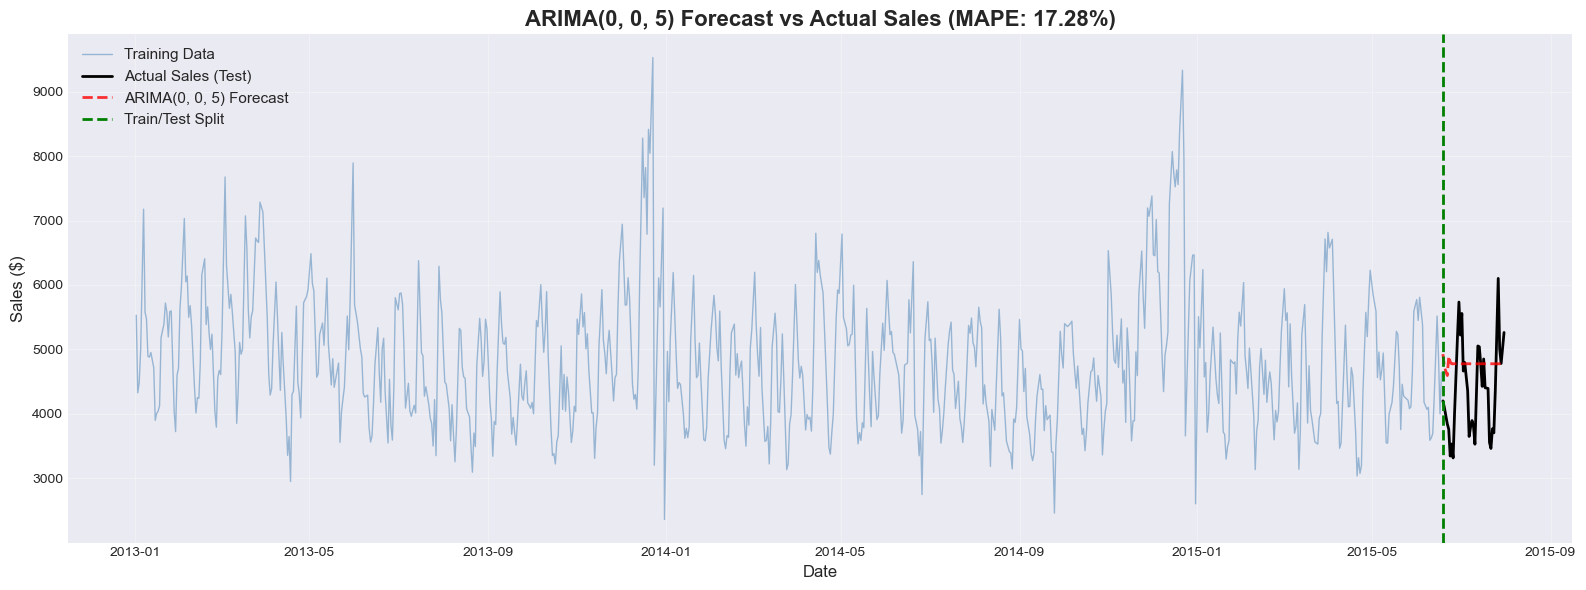

In [14]:
# Plot actual vs predicted
plt.figure(figsize=(16, 6))

# Training data
plt.plot(train['Date'], train['Sales'], label='Training Data', 
         linewidth=1, alpha=0.5, color='steelblue')

# Actual test data
plt.plot(test_arima['Date'], test_arima['Sales'], label='Actual Sales (Test)', 
         linewidth=2, color='black')

# ARIMA forecast
plt.plot(test_arima['Date'], test_arima['ARIMA_Forecast'], label=f'ARIMA{best_order} Forecast', 
         linewidth=2, alpha=0.8, color='red', linestyle='--')

plt.axvline(test_start_date, color='green', linestyle='--', linewidth=2, label='Train/Test Split')
plt.title(f'ARIMA{best_order} Forecast vs Actual Sales (MAPE: {mape_arima:.2f}%)', 
          fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

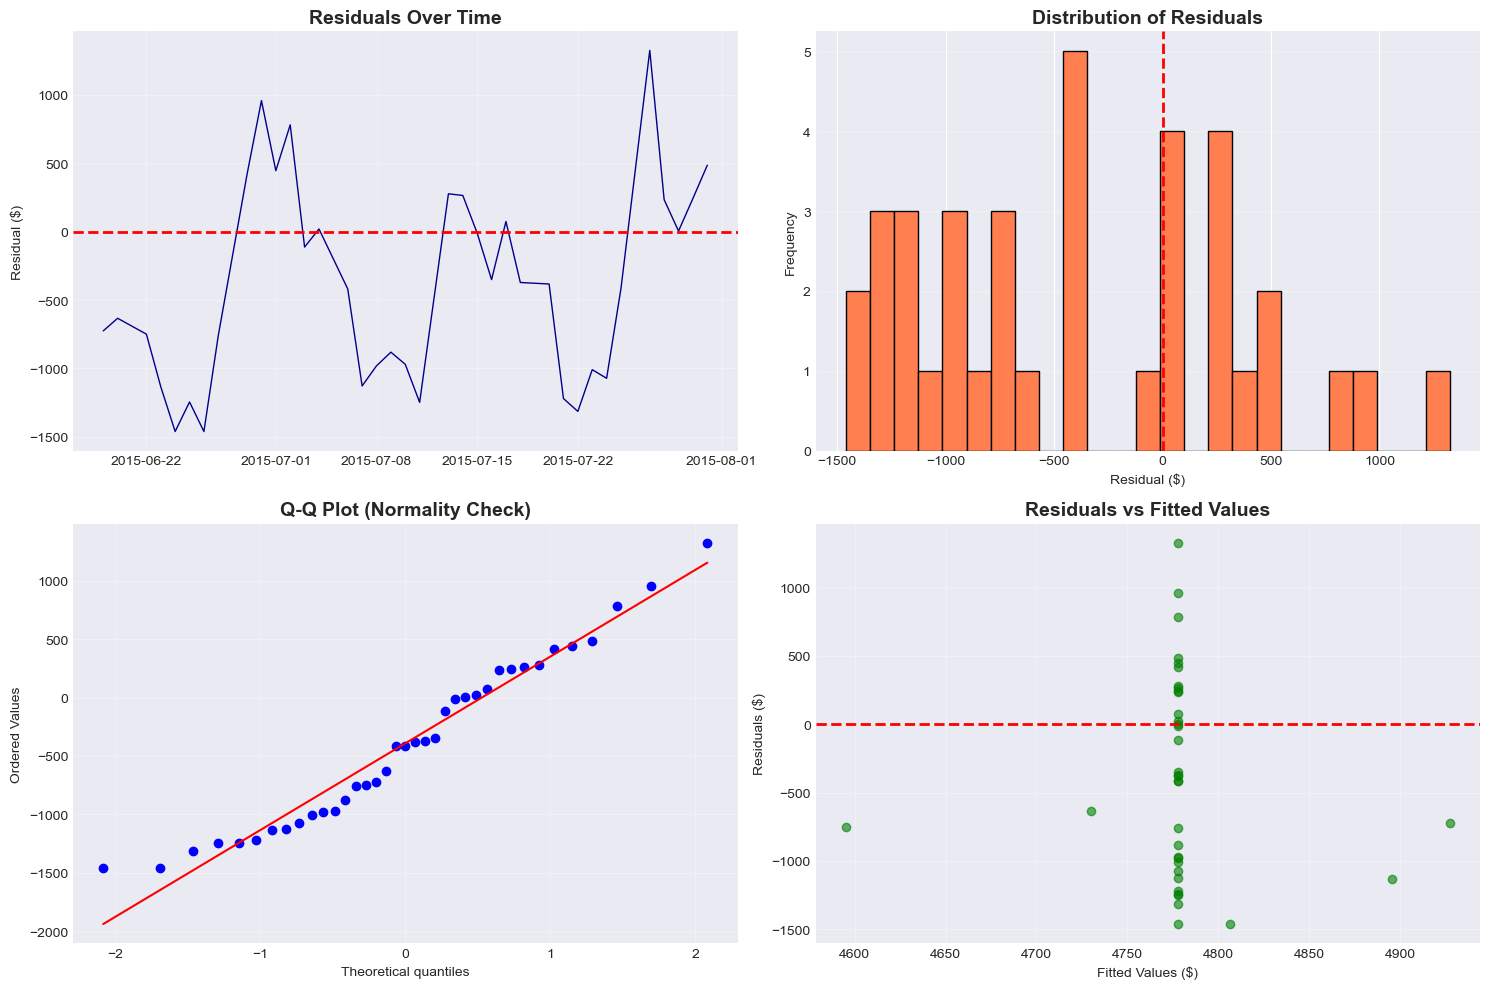

RESIDUAL DIAGNOSTICS
Mean residual: $-392.42 (should be close to 0)
Std deviation: $731.67

✅ Good residuals should be:
  - Randomly scattered around zero
  - Normally distributed (bell curve)
  - No obvious patterns


In [15]:
# Calculate residuals
residuals = test_arima['Sales'] - test_arima['ARIMA_Forecast']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuals over time
axes[0, 0].plot(test_arima['Date'], residuals, linewidth=1, color='darkblue')
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_title('Residuals Over Time', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Residual ($)')
axes[0, 0].grid(alpha=0.3)

# Histogram of residuals
axes[0, 1].hist(residuals, bins=25, edgecolor='black', color='coral')
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_title('Distribution of Residuals', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Residual ($)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(axis='y', alpha=0.3)

# Q-Q plot
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Normality Check)', fontsize=14, fontweight='bold')
axes[1, 0].grid(alpha=0.3)

# Residuals vs Fitted
axes[1, 1].scatter(test_arima['ARIMA_Forecast'], residuals, alpha=0.6, color='green')
axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1, 1].set_title('Residuals vs Fitted Values', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Fitted Values ($)')
axes[1, 1].set_ylabel('Residuals ($)')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("="*80)
print("RESIDUAL DIAGNOSTICS")
print("="*80)
print(f"Mean residual: ${residuals.mean():,.2f} (should be close to 0)")
print(f"Std deviation: ${residuals.std():,.2f}")
print(f"\n✅ Good residuals should be:")
print("  - Randomly scattered around zero")
print("  - Normally distributed (bell curve)")
print("  - No obvious patterns")

14-DAY FUTURE FORECAST


,Date,Forecast
0,2015-08-01,4777.655271
1,2015-08-02,4777.655271
2,2015-08-03,4777.655271
3,2015-08-04,4777.655271
4,2015-08-05,4777.655271
5,2015-08-06,4777.655271
6,2015-08-07,4777.655271
7,2015-08-08,4777.655271
8,2015-08-09,4777.655271
9,2015-08-10,4777.655271


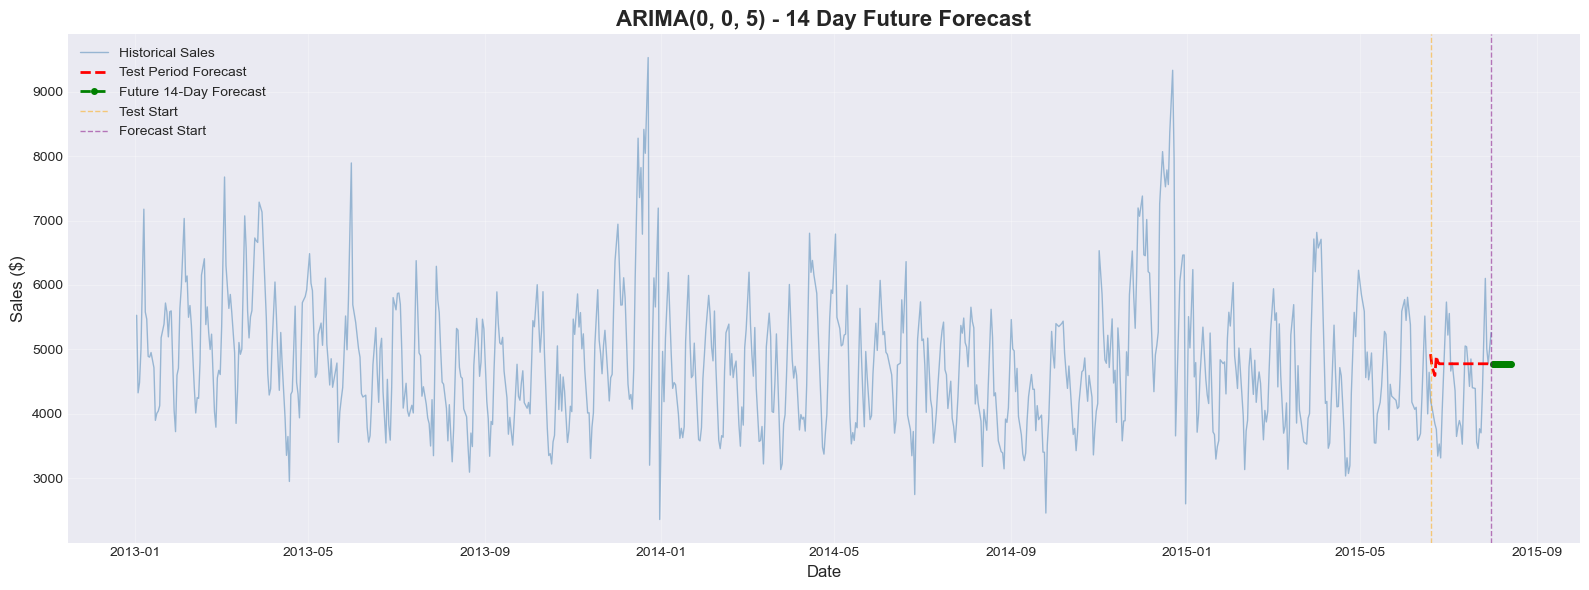

In [16]:
# Make 14-day forecast into the future
future_steps = 14
future_forecast = arima_fitted.forecast(steps=len(test) + future_steps)

# Get last date and create future dates
last_date = store_1_open['Date'].max()
future_dates = pd.date_range(start=last_date + timedelta(days=1), periods=future_steps, freq='D')

# Create dataframe
future_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast': future_forecast.values[-future_steps:]
})

print("="*80)
print(f"14-DAY FUTURE FORECAST")
print("="*80)
display(future_df)

# Visualize
plt.figure(figsize=(16, 6))
plt.plot(store_1_open['Date'], store_1_open['Sales'], label='Historical Sales', 
         linewidth=1, alpha=0.5, color='steelblue')
plt.plot(test_arima['Date'], test_arima['ARIMA_Forecast'], label='Test Period Forecast', 
         linewidth=2, color='red', linestyle='--')
plt.plot(future_df['Date'], future_df['Forecast'], label='Future 14-Day Forecast', 
         linewidth=2, color='green', linestyle='--', marker='o', markersize=4)
plt.axvline(test_start_date, color='orange', linestyle='--', linewidth=1, alpha=0.5, label='Test Start')
plt.axvline(last_date, color='purple', linestyle='--', linewidth=1, alpha=0.5, label='Forecast Start')
plt.title(f'ARIMA{best_order} - 14 Day Future Forecast', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
print("="*80)
print("TRYING SARIMA (Seasonal ARIMA)")
print("="*80)
print("Testing weekly seasonality (period=7)...\n")

try:
    # SARIMA with weekly seasonality
    sarima_model = SARIMAX(
        train['Sales'],
        order=best_order,
        seasonal_order=(1, 1, 1, 7),  # Weekly seasonality
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    sarima_fitted = sarima_model.fit(disp=False)
    
    # Forecast
    sarima_forecast = sarima_fitted.forecast(steps=len(test))
    test['SARIMA_Forecast'] = sarima_forecast.values
    
    # Evaluate
    mape_sarima = calculate_mape(test['Sales'], test['SARIMA_Forecast'])
    mae_sarima = mean_absolute_error(test['Sales'], test['SARIMA_Forecast'])
    
    print(f"✅ SARIMA Model Performance:")
    print(f"   MAPE: {mape_sarima:.2f}%")
    print(f"   MAE:  ${mae_sarima:,.2f}")
    
    print(f"\n📊 Comparison:")
    print(f"   Baseline (Naive):  {baseline_mape:.2f}%")
    print(f"   ARIMA:             {mape_arima:.2f}%")
    print(f"   SARIMA:            {mape_sarima:.2f}%")
    
    if mape_sarima < mape_arima:
        print(f"\n✅ SARIMA is better! Use this model.")
        best_model_type = "SARIMA"
        best_mape = mape_sarima
    else:
        print(f"\n✅ ARIMA is better. Stick with ARIMA.")
        best_model_type = "ARIMA"
        best_mape = mape_arima
        
except Exception as e:
    print(f"⚠️ SARIMA failed: {e}")
    print("This is OK - ARIMA is sufficient!")
    best_model_type = "ARIMA"
    best_mape = mape_arima

TRYING SARIMA (Seasonal ARIMA)
Testing weekly seasonality (period=7)...

✅ SARIMA Model Performance:
   MAPE: 16.93%
   MAE:  $683.45

📊 Comparison:
   Baseline (Naive):  9.65%
   ARIMA:             17.28%
   SARIMA:            16.93%

✅ SARIMA is better! Use this model.


In [18]:
import pickle
import os

# Create directories
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/models', exist_ok=True)
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables', exist_ok=True)

# Save model
model_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/models/arima_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(arima_fitted, f)
print(f"✅ Model saved: {model_path}")

# Save predictions
predictions_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/arima_predictions.csv'
test_arima.to_csv(predictions_path, index=False)
print(f"✅ Predictions saved: {predictions_path}")

# Save future forecast
future_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/arima_future_forecast.csv'
future_df.to_csv(future_path, index=False)
print(f"✅ Future forecast saved: {future_path}")

# Save comparison results
results = pd.DataFrame({
    'Model': ['Baseline (Naive)', 'ARIMA'],
    'MAPE': [baseline_mape, mape_arima],
    'MAE': [440, mae_arima],  # Your baseline MAE
    'RMSE': [None, rmse_arima],
    'R2': [None, r2_arima]
})

results_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/arima_comparison.csv'
results.to_csv(results_path, index=False)
print(f"✅ Comparison results saved: {results_path}")

✅ Model saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/models/arima_model.pkl
✅ Predictions saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/arima_predictions.csv
✅ Future forecast saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/arima_future_forecast.csv
✅ Comparison results saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/arima_comparison.csv


In [19]:
print("="*80)
print("TRYING MANUAL ARIMA PARAMETERS")
print("="*80)
print("Auto ARIMA gave us (0,0,5) which ignored autocorrelation.")
print("Let's try parameters that use past sales values...\n")

# Make sure ARIMA is imported
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

# Define MAPE function again
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Try different ARIMA orders
manual_orders = [
    (1, 0, 0),  # Pure AR(1) - use yesterday
    (2, 0, 0),  # AR(2) - use last 2 days
    (7, 0, 0),  # AR(7) - use last week
    (1, 0, 1),  # ARIMA(1,0,1) - balanced
    (2, 0, 2),  # ARIMA(2,0,2) - balanced
    (1, 1, 1),  # ARIMA(1,1,1) - with differencing
]

results_manual = []

for order in manual_orders:
    try:
        print(f"Testing ARIMA{order}...", end=" ")
        
        # Train model
        model = ARIMA(train['Sales'], order=order)
        fitted = model.fit()
        
        # Forecast
        forecast = fitted.forecast(steps=len(test))
        
        # Evaluate
        mape = calculate_mape(test['Sales'], forecast)
        mae = mean_absolute_error(test['Sales'], forecast)
        
        results_manual.append({
            'Order': f"ARIMA{order}",
            'MAPE': mape,
            'MAE': mae
        })
        
        print(f"MAPE = {mape:.2f}%, MAE = ${mae:.2f}")
        
    except Exception as e:
        print(f"Failed - {str(e)[:50]}")

TRYING MANUAL ARIMA PARAMETERS
Auto ARIMA gave us (0,0,5) which ignored autocorrelation.
Let's try parameters that use past sales values...

Testing ARIMA(1, 0, 0)... MAPE = 17.05%, MAE = $682.29
MAPE = 17.00%, MAE = $680.28
MAPE = 17.20%, MAE = $687.94
Testing ARIMA(1, 0, 1)... MAPE = 17.01%, MAE = $680.81
MAPE = 17.38%, MAE = $695.06
MAPE = 17.00%, MAE = $680.71
